# TurboSensor: exploration and results

Remaining-useful-life (RUL) prediction on NASA's C-MAPSS turbofan simulation data.
This notebook walks through what the data looks like, why the pipeline is built the
way it is, and how the trained model performs, both as a regressor and as a
maintenance-alert system.

All modelling code lives in the `turbosensor` package; the notebook only calls it.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from turbosensor.data import SENSOR_COLS, SENSOR_DESCRIPTIONS, SETTING_COLS, add_rul, load_subset
from turbosensor.evaluation import error_by_rul_bucket, regression_report
from turbosensor.maintenance import maintenance_plan
from turbosensor.model import RULModel
from turbosensor.preprocessing import ConditionNormalizer

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, ART, FIG = ROOT / "data/raw", ROOT / "artifacts", ROOT / "reports/figures"
FIG.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#8a8984", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.titlesize": 11,
    "axes.titlecolor": INK, "lines.linewidth": 1.6, "font.size": 9,
})

## 1. The data

Each engine starts healthy with unknown initial wear, develops a fault, and runs until failure (training) or is cut off some time before failure (test).

In [2]:
split = load_subset("FD001", DATA)
train = add_rul(split.train, cap=None)
life = train.groupby("unit")["cycle"].max()
print(f"{split.train.unit.nunique()} training engines, {len(split.train):,} cycles")
print(f"engine life: min {life.min()}, median {life.median():.0f}, max {life.max()} cycles")
print(f"{split.test.unit.nunique()} test engines; true RUL at cut-off ranges {split.test_rul.min()}-{split.test_rul.max()}")
split.train.head()

100 training engines, 20,631 cycles
engine life: min 128, median 199, max 362 cycles
100 test engines; true RUL at cut-off ranges 7-145


,unit,cycle,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


### Which sensors carry signal?

Seven of the 21 sensors are constant (or nearly) in FD001; the rest drift as the engine degrades. The pipeline drops the flat ones automatically.

In [3]:
std = split.train[SENSOR_COLS].std()
corr = train[SENSOR_COLS + ["rul_true"]].corr()["rul_true"].drop("rul_true")
summary = pd.DataFrame({"description": pd.Series(SENSOR_DESCRIPTIONS), "std": std, "corr_with_rul": corr}).round(3)
summary.sort_values("corr_with_rul", key=abs, ascending=False)

,description,std,corr_with_rul
s_11,Static pressure at HPC outlet (Ps30),0.267,-0.696
s_4,Total temperature at LPT outlet (T50),9.001,-0.679
s_12,Ratio of fuel flow to Ps30 (phi),0.738,0.672
s_7,Total pressure at HPC outlet (P30),0.885,0.657
s_15,Bypass ratio (BPR),0.038,-0.643
s_21,LPT coolant bleed (W32),0.108,0.636
s_20,HPT coolant bleed (W31),0.181,0.629
s_2,Total temperature at LPC outlet (T24),0.500,-0.606
s_17,Bleed enthalpy (htBleed),1.549,-0.606
s_3,Total temperature at HPC outlet (T30),6.131,-0.585


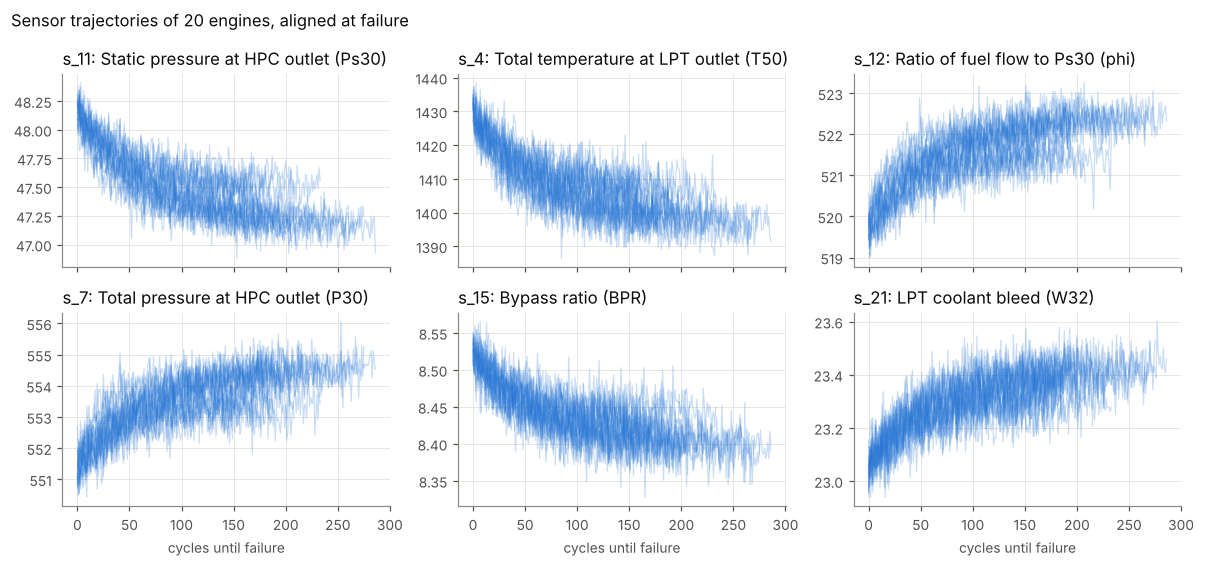

In [4]:
show = ["s_11", "s_4", "s_12", "s_7", "s_15", "s_21"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.2), sharex=True)
for ax, s in zip(axes.flat, show):
    for u in range(1, 21):
        g = train[train.unit == u]
        ax.plot(g.rul_true, g[s], color=BLUE, alpha=0.25, lw=0.8)
    ax.invert_xaxis()
    ax.set_title(f"{s}: {SENSOR_DESCRIPTIONS[s]}", loc="left")
for ax in axes[1]:
    ax.set_xlabel("cycles until failure")
fig.suptitle("Sensor trajectories of 20 engines, aligned at failure", x=0.01, ha="left", color=INK)
fig.tight_layout()
fig.savefig(FIG / "sensor_trajectories.png", bbox_inches="tight")

Degradation is invisible for most of an engine's life and only bends the sensors in the last ~100-150 cycles. That is why the target is **capped at 125 cycles** (piecewise-linear RUL): asking a model to tell 250 from 200 cycles left on an engine that shows no wear is asking it to memorise noise.

### Operating conditions (FD002 / FD004)

The multi-condition subsets fly in six regimes. Raw sensor values jump between regimes by far more than degradation moves them, so each sensor is standardised against its own regime's statistics.

cycles flown in each regime: [13458  8096  8002  8044  8037  8122]


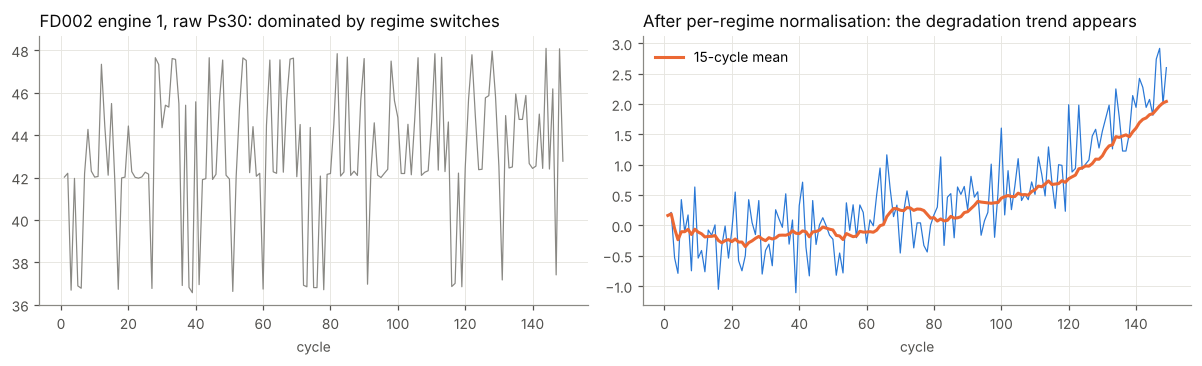

In [5]:
fd2 = load_subset("FD002", DATA)
norm = ConditionNormalizer().fit(fd2.train)
regimes = norm.regimes(fd2.train)
z = norm.transform(fd2.train)
u1 = fd2.train.unit == 1
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(fd2.train.loc[u1, "cycle"], fd2.train.loc[u1, "s_11"], color=GRAY, lw=0.8)
axes[0].set_title("FD002 engine 1, raw Ps30: dominated by regime switches", loc="left")
axes[1].plot(z.loc[u1, "cycle"], z.loc[u1, "s_11"], color=BLUE, lw=0.8)
axes[1].plot(z.loc[u1, "cycle"], z.loc[u1, "s_11"].rolling(15, min_periods=1).mean(), color=ORANGE, lw=2, label="15-cycle mean")
axes[1].set_title("After per-regime normalisation: the degradation trend appears", loc="left")
axes[1].legend(frameon=False)
for ax in axes:
    ax.set_xlabel("cycle")
fig.tight_layout()
fig.savefig(FIG / "regime_normalisation.png", bbox_inches="tight")
print("cycles flown in each regime:", np.bincount(regimes))

## 2. Results on the official test sets

Models were trained with `turbosensor train --config configs/fdXXX.yaml` (see README). Each engine in the test set is scored at its last observed cycle, against NASA's ground truth.

Two numbers are reported for each:
* **RMSE vs true RUL**: the strict number.
* **RMSE vs capped truth**: the protocol most papers use (truth capped at 125 like the target).

The NASA score is the asymmetric PHM08 metric that punishes late predictions harder than early ones.

In [6]:
rows = []
for s in ["FD001", "FD002", "FD003", "FD004"]:
    m = json.loads((ART / s / "metrics.json").read_text())["models"]
    for kind, r in m.items():
        rows.append({"subset": s, "model": kind, "RMSE": r["rmse"], "RMSE (capped)": r["capped"]["rmse"],
                     "NASA score": r["nasa_score"], "NASA (capped)": r["capped"]["nasa_score"],
                     "CV RMSE": r["cv_rmse"], "80% interval coverage (capped)": r["capped"].get("interval_coverage"),
                     "missed @30": r["maintenance"]["missed"], "false alarms @30": r["maintenance"]["false_alarms"], "cycles early per false alarm": r["maintenance"]["false_alarm_mean_cycles_early"]})
results = pd.DataFrame(rows).set_index(["subset", "model"]).round(2)
results

RMSE  RMSE (capped)  NASA score  NASA (capped)  CV RMSE  \
subset model                                                             
FD001  ridge  15.73          14.19      344.53         289.34    13.86   
       lgbm   12.15          10.85      193.40         166.06     8.65   
FD002  ridge  26.13          14.15     5874.25         856.69    13.89   
       lgbm   22.65           9.95     3646.02         432.33     9.66   
FD003  ridge  16.19          14.31      434.16         364.46    13.13   
       lgbm   10.89           9.10      194.44         162.26     8.45   
FD004  ridge  28.09          15.73     5441.82        1126.74    15.08   
       lgbm   23.66          10.75     3142.45         568.90    10.76   

              80% interval coverage (capped)  missed @30  false alarms @30  \
subset model                                                                 
FD001  ridge                            0.84           0                 3   
       lgbm                             0.67           0                 3   
FD002  ridge                            0.77           0                12   
       lgbm                             0.78           0                13   
FD003  ridge                            0.79           0                 6   
       lgbm                             0.74           0                 2   
FD004  ridge                            0.78           2                13   
       lgbm                             0.76           0                16   

              cycles early per false alarm  
subset model                                
FD001  ridge                          6.33  
       lgbm                           6.33  
FD002  ridge                         10.17  
       lgbm                           7.31  
FD003  ridge                         10.17  
       lgbm                           3.00  
FD004  ridge                         10.54  
       lgbm                           5.69

{'rmse': 12.147355913105113,
 'mae': 8.813037397698217,
 'nasa_score': 193.4030988739372,
 'late_rate': 0.51,
 'n': 100,
 'interval_coverage': 0.61,
 'interval_width': 18.47406349947456}

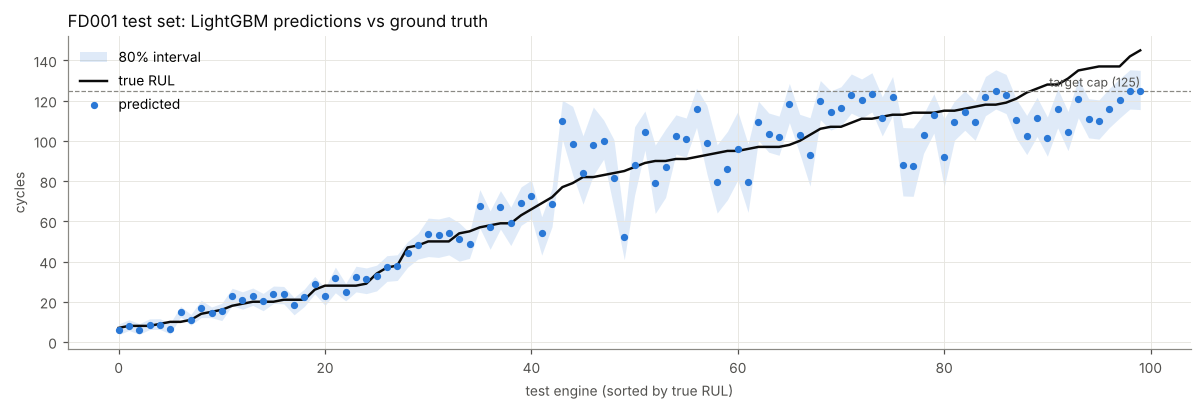

In [7]:
model = RULModel.load(ART / "FD001/lgbm.joblib")
latest = model.predict_latest(split.test)
latest["rul_true"] = split.test_rul.loc[latest.unit].to_numpy()
order = latest.sort_values("rul_true").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(order))
ax.fill_between(x, order.rul_lower, order.rul_upper, color=BLUE, alpha=0.15, lw=0, label="80% interval")
ax.plot(x, order.rul_true, color=INK, lw=1.6, label="true RUL")
ax.scatter(x, order.rul_pred, color=BLUE, s=14, zorder=3, label="predicted")
ax.axhline(125, color=GRAY, ls="--", lw=0.8)
ax.text(len(order) - 1, 127, "target cap (125)", ha="right", color=MUTED, fontsize=8)
ax.set_xlabel("test engine (sorted by true RUL)"); ax.set_ylabel("cycles")
ax.set_title("FD001 test set: LightGBM predictions vs ground truth", loc="left")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "fd001_predictions.png", bbox_inches="tight")
regression_report(latest.rul_true, latest.rul_pred, latest.rul_lower, latest.rul_upper)

Errors are small exactly where they matter, close to failure. The large errors sit on engines with more than 125 cycles left, which the model deliberately reports as "healthy, at least 125".

In [8]:
error_by_rul_bucket(latest.rul_true, latest.rul_pred).round(1)

,bucket,n,rmse,bias
0,"[0.0, 25.0)",19.0,2.5,0.8
1,"[25.0, 50.0)",11.0,2.8,0.1
2,"[50.0, 75.0)",13.0,6.7,1.1
3,"[75.0, 100.0)",23.0,15.5,4.8
4,"[100.0, 125.0)",23.0,12.7,-2.2
5,"[125.0, inf)",11.0,20.9,-20.2


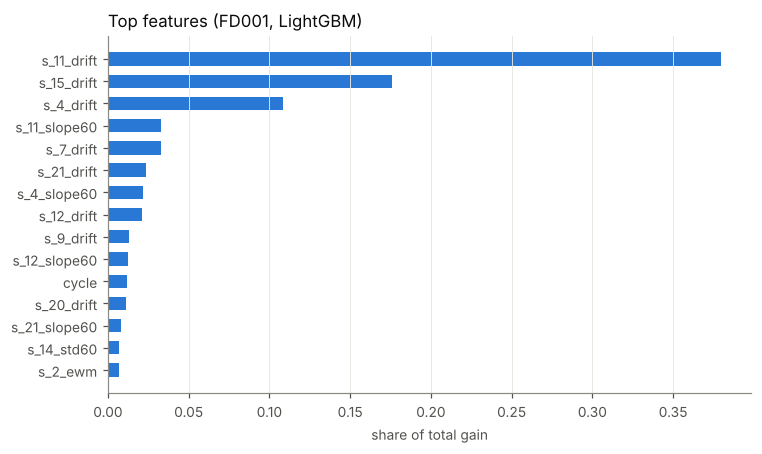

In [9]:
imp = model.feature_importance(15)[::-1]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(imp.index, imp.values, color=BLUE, height=0.6)
ax.set_xlabel("share of total gain")
ax.set_title("Top features (FD001, LightGBM)", loc="left")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "fd001_feature_importance.png", bbox_inches="tight")

## 3. From prediction to maintenance decision

The planner asks one question per engine: will it fail within the next 30 cycles? Two mistakes cost different amounts:

* **missed failure**: an unscheduled removal, priced at 100 cycles of engine life;
* **false alarm**: the engine is pulled while it still has life left; the cost is the cycles thrown away.

The alert threshold that minimises this cost is learned from **out-of-fold predictions on the training engines** (never the test set) and stored in the model.

In [10]:
print("learned alert thresholds (horizon -> pull when predicted RUL <=):", {h: model.alert_thresholds_[h] for h in (20, 30, 40)})
plan = maintenance_plan(latest, horizon=30, watch=60, thresholds=model.alert_thresholds_)
print(plan.action.value_counts().to_string())
plan.head(10).round(1)

learned alert thresholds (horizon -> pull when predicted RUL <=): {20: 26.5, 30: 38.5, 40: 50.0}
action
ok         57
replace    28
watch      15


,unit,cycle,rul_pred,rul_lower,rul_upper,rul_true,alert_threshold,action
0,34,203,6.0,3.6,8.9,7,38.5,replace
1,81,213,6.1,3.8,9.1,8,38.5,replace
2,76,205,6.3,4.0,9.3,10,38.5,replace
3,31,196,8.1,5.7,11.0,8,38.5,replace
4,68,187,8.5,6.2,11.5,8,38.5,replace
5,82,162,8.6,6.2,11.6,9,38.5,replace
6,35,198,10.7,8.3,13.7,11,38.5,replace
7,56,136,14.4,12.1,17.4,15,38.5,replace
8,42,156,14.8,12.4,17.8,10,38.5,replace
9,20,184,15.3,10.6,19.3,16,38.5,replace


In [11]:
truth = plan.rul_true <= 30
alert = plan.action == "replace"
early = plan.loc[alert & ~truth, "rul_true"] - 30
print(f"false alarms are pulled on average {early.mean():.1f} cycles before the 30-cycle horizon (max {early.max():.0f})")
pd.crosstab(truth.rename("fails within 30 cycles"), alert.rename("replace alert"))

false alarms are pulled on average 6.3 cycles before the 30-cycle horizon (max 8)


replace alert,False,True
fails within 30 cycles,,
False,72,3
True,0,25


## Takeaways

* Regime normalisation plus causal rolling features over 5-60 cycles (level, noise, trend, drift from the engine's own baseline) and a 3-seed ensemble let a gradient-boosted model reach strong accuracy without a GPU.
* Validation is grouped by engine, so no engine is ever in both training and validation folds.
* Out-of-fold residuals give a calibrated interval per engine, and a cost-based alert threshold learned on training engines turns predictions into replace/watch/ok decisions.
* The weakest region is engines with more than 125 cycles left: they are reported as healthy, which is the intended behaviour, but it is what drives raw RMSE on FD002/FD004, where over a fifth of test engines are in that range.